# Aula 8 - Testes Paramétricos

## 1. Preparando os dados

In [6]:
# importa as bibliotecas e define o tema dos gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

sns.set_theme(style="whitegrid", palette="colorblind")

In [14]:
# carrega as cinco bases usadas na aula (cada caso usa uma delas)
mtcars = pd.read_csv("data/mtcars.csv")
penguins = pd.read_csv("data/penguins.csv")
sleep = pd.read_csv("data/sleep.csv")
iris = pd.read_csv("data/iris.csv")
titanic = pd.read_csv("data/titanic.csv")

### 1.1 Conhecendo as bases

- **penguins**: 344 pinguins de três ilhas da Antártida. Tem espécie, ilha, medidas do bico, nadadeira, massa (g), sexo e ano.
- **sleep**: ensaio clínico de 1908, com 10 pacientes que testaram 2 soníferos. `extra` = horas de sono a mais, `group` = droga e `ID` = paciente.
- **iris**: 150 flores de 3 espécies (50 de cada), com comprimento e largura da sépala e da pétala.
- **titanic**: 891 passageiros. `survived` (0/1), `pclass` (classe), `sex`, `age`, `fare` (tarifa), `embarked` (porto) etc.

In [ ]:
# cinco primeiras linhas de cada csv
penguins.head()

,species,island,bill_len,bill_dep,flipper_len,body_mass,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [ ]:
sleep.head()

,extra,group,ID
0,0.7,1,1
1,-1.6,1,2
2,-0.2,1,3
3,-1.2,1,4
4,-0.1,1,5


In [10]:
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [15]:
# algumas colunas repetem a informação: class/pclass, alive/survived, embark_town/embarked
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 2. O que um teste paramétrico exige

Um teste paramétrico não simula a distribuição nula. Ele supõe que os dados seguem uma curva conhecida e lê o p-valor como uma área sob essa curva. Isso só é confiável se as premissas valerem:

| Premissa | O que afirma | Se falhar |
|---|---|---|
| Normalidade | os dados (ou resíduos) seguem uma normal | o p-valor fica errado em amostras pequenas |
| Homocedasticidade | variâncias iguais entre os grupos | usar a versão de Welch |
| Independência | uma observação não influencia a outra | mudar o desenho do teste, por exemplo para o pareado |

### 2.3 Verificando a normalidade
- Q-Q plot: compara os quantis dos dados com os de uma normal. Se os dados forem normais, os pontos ficam sobre a reta. Uma curva em U indica assimetria à direita.
- Shapiro-Wilk: H₀ = "os dados são normais". Se p < 0,05, rejeitamos a normalidade.

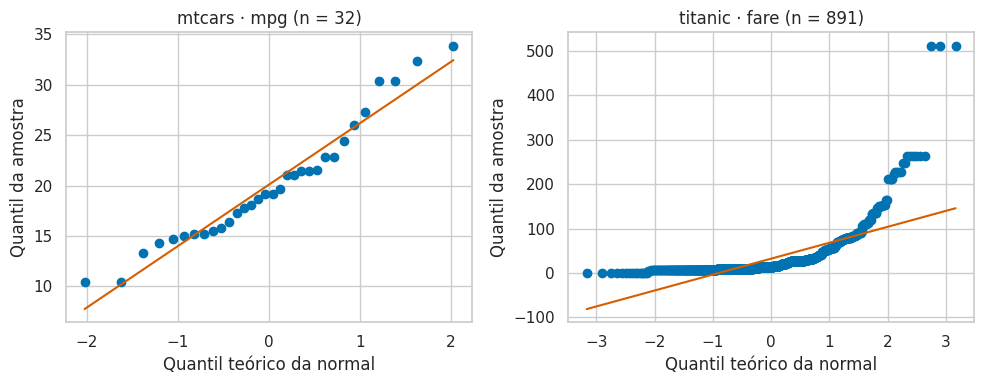

,W,p
mpg,0.947565,1.228814e-01
fare,0.521891,1.084044e-43


In [ ]:
# Q-Q plot e Shapiro-Wilk em duas variáveis reais
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# zip anda pelas três listas juntas: um eixo, uma variável e um título por vez
for ax, values, title in zip(
  axes,
  [mtcars["mpg"], titanic["fare"]],
  ["mtcars · mpg (n = 32)", "titanic · fare (n = 891)"],
):
  # probplot ordena os valores e compara com os quantis da normal
  # plot=ax desenha os pontos e a reta de referência
  stats.probplot(values, dist="norm", plot=ax)
  ax.set(title=title, xlabel="Quantil teórico da normal", ylabel="Quantil da amostra")

plt.tight_layout()
plt.show()

# shapiro devolve (W, p); W perto de 1 = forma parecida com a normal
pd.DataFrame(
  {
    "mpg": stats.shapiro(mtcars["mpg"]),
    "fare": stats.shapiro(titanic["fare"]),
  },
  index=["W", "p"],
).T

- mpg: os pontos seguem a reta, W ≈ 0,95 e p ≈ 0,12, então não rejeitamos a normalidade.
- fare: o gráfico forma uma curva forte (assimetria à direita), W ≈ 0,52 e p ≈ 0, então não é normal

com n pequeno, o Shapiro tem pouco poder. Com n grande, ele rejeita desvios minúsculos. Por isso, sempre olhe o Q-Q plot junto.

### 2.4–2.6 Como escolher o teste
Três perguntas, nesta ordem: objetivo (médias, proporções ou associação), escala (contínua, binária ou nominal) e desenho (1 amostra, 2 grupos ou 3+; independentes ou pareados).

| Objetivo | Teste | Caso |
|---|---|---|
| média contra uma meta | t de uma amostra | 1 · mtcars |
| médias de 2 grupos | t de Welch | 2 · penguins |
| antes e depois (mesmas pessoas) | t pareado | 3 · sleep |
| médias de 3+ grupos | ANOVA + Tukey | 4 · iris |
| associação linear | Pearson | 5 · mtcars |
| proporções de 2 grupos | Z de duas proporções | 6 · titanic |
| associação entre categorias | qui-quadrado | 7 · titanic |

## 3. Conceitos importantes (resumo)
- Estatística de teste = sinal ÷ ruído (efeito ÷ variação esperada pelo acaso).
- Graus de liberdade (gl) escolhem qual curva t, F ou χ² usar. Menos gl significa caudas mais pesadas, e aí é preciso uma estatística maior para rejeitar H₀.
- Intervalo de confiança (IC 95%): média ± t_crit × SE. Se o IC não contém o valor de H₀, rejeitamos H₀.

## 4. Sete casos, sete testes
Antes dos casos, uma função que resume o resultado de qualquer teste em uma linha:

In [17]:
# resume o resultado de um teste em uma linha legível
def report(name, result, stat="estatística", df=None):
    # alguns testes (como proportions_ztest) devolvem só uma tupla (estatística, p)
    if isinstance(result, tuple):
        value, p = result
    else:
        value, p = result.statistic, result.pvalue
    # getattr busca os graus de liberdade no resultado; devolve None se o teste não tiver
    df = df if df is not None else getattr(result, "df", None)

    parts = [f"{stat} = {value:.3f}"]
    if df is not None:
        parts.append(f"gl = {df:.4g}" if np.isscalar(df) else f"gl = {df}")
    parts.append("p < 0.001" if p < 0.001 else f"p = {p:.3f}")
    # testes t e Pearson têm .confidence_interval(), que dá o IC de 95%
    if hasattr(result, "confidence_interval"):
        ci = result.confidence_interval()
        parts.append(f"IC 95% [{ci.low:.2f} ; {ci.high:.2f}]")

    print(f"{name}: " + " · ".join(parts))

### Caso 1. Teste t de uma amostra

**Cenário:** o consumo médio da frota (32 carros) atende à meta de 20 mpg?
- H₀: μ = 20
- H₁: μ ≠ 20

Fórmula: t = (média − meta) / SE, com SE = s / √n e gl = n − 1.

In [18]:
# teste t de uma amostra, passo a passo
mpg = mtcars["mpg"]
target = 20  # meta (valor de H₀)

n = len(mpg)
se = mpg.std() / np.sqrt(n)          # erro-padrão; .std() do pandas já usa n - 1
t = (mpg.mean() - target) / se       # quantos erros-padrão a média está longe da meta
p = 2 * stats.t.sf(abs(t), df=n - 1) # sf = área da cauda direita; ×2 porque é bilateral

In [20]:
print(f"média = {mpg.mean():.3f}")
print(f"dp = {mpg.std():.3f}")
print(f"erro-padrão = {se:.3f}")
print(f"t = {t:.3f}")
print(f"gl = {n - 1}")
print(f"p = {p:.3f}")

média = 20.091
dp = 6.027
erro-padrão = 1.065
t = 0.085
gl = 31
p = 0.933


In [21]:
# o mesmo teste com o SciPy (dá o mesmo t e p, e ainda o intervalo de confiança)
case1 = stats.ttest_1samp(mpg, popmean=target)

report("t de uma amostra", case1, stat="t")

t de uma amostra: t = 0.085 · gl = 31 · p = 0.933 · IC 95% [17.92 ; 22.26]


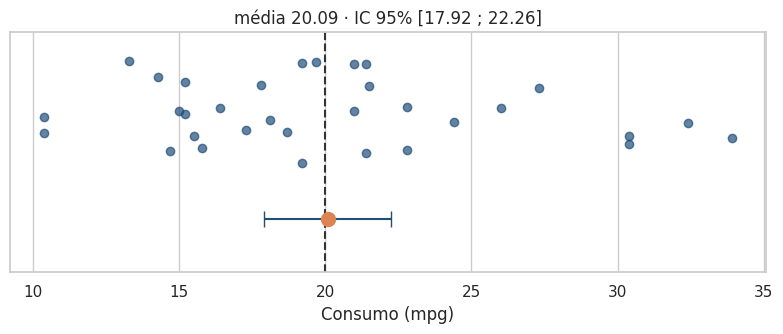

In [22]:
# pontos, média e intervalo de confiança em relação a um valor de referência
# (função reaproveitada no caso 3)
def plot_mean_ci(values, ci, ref, xlabel, ax):
    # altura aleatória só para os pontos não ficarem um em cima do outro (o eixo y não significa nada)
    jitter = np.random.default_rng(1).uniform(0.6, 1.4, len(values))
    ax.scatter(values, jitter, color="#1F4E79", alpha=.7)
    # tamanho da barra de erro para a esquerda e para a direita da média
    error = [[values.mean() - ci.low], [ci.high - values.mean()]]
    ax.errorbar(values.mean(), 0.2, xerr=error, fmt="o", color="#DD8452",
                ecolor="#1F4E79", capsize=6, markersize=10)
    ax.axvline(ref, color="#333333", linestyle="--")  # linha da meta / valor de H₀
    ax.set(xlabel=xlabel, yticks=[], ylim=(-0.2, 1.6),
           title=f"média {values.mean():.2f} · IC 95% [{ci.low:.2f} ; {ci.high:.2f}]")

fig, ax = plt.subplots(figsize=(8, 3.5))
plot_mean_ci(mpg, case1.confidence_interval(), target, "Consumo (mpg)", ax)
plt.tight_layout()
plt.show()

**Interpretação:** média de 20,09 mpg, t ≈ 0,09 e p ≈ 0,93. O IC [17,9 ; 22,3] contém 20. **Não rejeitamos H₀.** Isso **não prova** que μ = 20: os dados só são *compatíveis* com a meta, assim como com qualquer valor dentro do IC.

### Caso 2. Teste t de Welch

**Cenário:** machos e fêmeas de pinguim têm massas médias diferentes?
- H₀: μ_machos = μ_fêmeas
- H₁: μ_machos ≠ μ_fêmeas

O Welch **não exige variâncias iguais**: cada grupo entra com a sua própria variância no erro-padrão.

In [23]:
# remove os 11 pinguins sem sexo (e sem massa) registrados
penguins_sex = penguins.dropna(subset=["sex", "body_mass"])

males = penguins_sex.loc[penguins_sex["sex"] == "male", "body_mass"]
females = penguins_sex.loc[penguins_sex["sex"] == "female", "body_mass"]

In [24]:
# resumo por sexo e a parcela s²/n de cada grupo (a incerteza da média de cada grupo)
welch_table = (
    penguins_sex
    .groupby("sex")
    .body_mass
    .agg(n="size", média="mean", dp="std")
    .assign(s2_n=lambda df: df["dp"] ** 2 / df["n"])
)

welch_table.round(1)

,n,média,dp,s2_n
sex,,,,
female,165,3862.3,666.2,2689.6
male,168,4545.7,787.6,3692.6


In [25]:
# erro-padrão da diferença = raiz da soma das duas parcelas s²/n
se_diff = np.sqrt(welch_table["s2_n"].sum())
t_manual = (males.mean() - females.mean()) / se_diff

# equal_var=False -> versão de Welch
case2 = stats.ttest_ind(males, females, equal_var=False)

print(f"erro-padrão da diferença = {se_diff:.1f} g")
print(f"t calculado à mão = {t_manual:.2f}")
report("t de Welch", case2, stat="t")

erro-padrão da diferença = 79.9 g
t calculado à mão = 8.55
t de Welch: t = 8.555 · gl = 323.9 · p < 0.001 · IC 95% [526.25 ; 840.58]


In [26]:
# verifica as variâncias, mostra o IC da diferença e quanto os grupos se sobrepõem
ci = case2.confidence_interval()

# Levene: H₀ = variâncias iguais; p < 0,05 justifica usar Welch
print(f"Levene: p = {stats.levene(males, females).pvalue:.3f}")
print(f"IC 95% da diferença: [{ci.low:.0f} ; {ci.high:.0f}] g")
# média de True/False = proporção de fêmeas mais pesadas que o macho médio
print(f"fêmeas acima do macho médio: {(females > males.mean()).mean():.0%}")

Levene: p = 0.014
IC 95% da diferença: [526 ; 841] g
fêmeas acima do macho médio: 25%


In [27]:
# função reaproveitável: cada observação (pontos) e a média de cada grupo (traço laranja)
def plot_group_means(data, x, y, order, ylabel, ax):
    sns.stripplot(data=data, x=x, y=y, order=order, ax=ax,
                  color="#1F4E79", alpha=.5, jitter=.25)
    means = data.groupby(x)[y].mean().reindex(order)  # reindex põe as médias na ordem do gráfico
    # hlines desenha um traço horizontal na média de cada grupo
    ax.hlines(means, np.arange(len(order)) - .35, np.arange(len(order)) + .35,
              color="#DD8452", linewidth=3)
    ax.set(xlabel="", ylabel=ylabel)

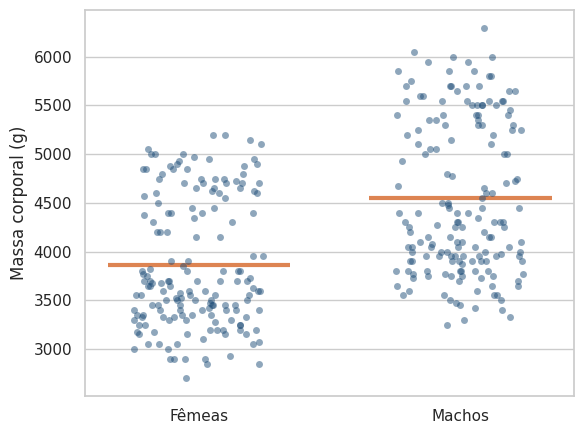

In [28]:
fig, ax = plt.subplots(figsize=(6, 4.5))
plot_group_means(penguins_sex, "sex", "body_mass", ["female", "male"],
                 "Massa corporal (g)", ax)
ax.set_xticks([0, 1], ["Fêmeas", "Machos"])  # troca os rótulos para português
plt.tight_layout()
plt.show()

Interpretação: machos pesam 4.546 g e fêmeas, 3.862 g (diferença de 683 g), com t ≈ 8,55 e p < 0,001. 
Rejeitamos H₀: há dimorfismo sexual. O Levene (p ≈ 0,014) mostra variâncias diferentes, o que justifica o Welch. Os grupos se sobrepõem (25% das fêmeas pesam mais que o macho médio): o teste fala de médias, não de cada indivíduo.

#### Existe dimorfismo dentro de cada espécie?
A base mistura 3 espécies de tamanhos bem diferentes. Isso infla o desvio-padrão dentro de cada sexo.

In [29]:
# média e desvio-padrão da massa por espécie e sexo
(
    penguins_sex
    .groupby(["species", "sex"])
    .body_mass
    .agg(["size", "mean", "std"])
    .round(0)
)

size    mean    std
species   sex                        
Adelie    female    73  3369.0  269.0
          male      73  4043.0  347.0
Chinstrap female    34  3527.0  285.0
          male      34  3939.0  362.0
Gentoo    female    58  4680.0  282.0
          male      61  5485.0  313.0

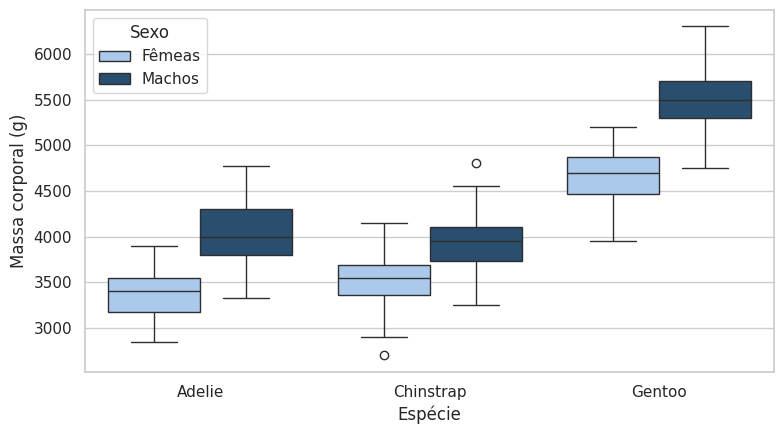

In [30]:
# massa por espécie, com machos e fêmeas lado a lado
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.boxplot(
    data=penguins_sex,
    x="species",
    y="body_mass",
    order=["Adelie", "Chinstrap", "Gentoo"],
    hue="sex",                      # uma caixa por sexo dentro de cada espécie
    hue_order=["female", "male"],
    palette={"female": "#A1C9F4", "male": "#1F4E79"},
    ax=ax,
)
ax.set(xlabel="Espécie", ylabel="Massa corporal (g)")

# reaproveita as cores da legenda e só troca os textos para português
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Fêmeas", "Machos"], title="Sexo")

plt.tight_layout()
plt.show()

In [31]:
# teste de Welch separado em cada espécie
# groupby devolve pares (nome da espécie, sub-tabela daquela espécie)
for species, group in penguins_sex.groupby("species"):
    male = group.loc[group["sex"] == "male", "body_mass"]
    female = group.loc[group["sex"] == "female", "body_mass"]
    report(species, stats.ttest_ind(male, female, equal_var=False), stat="t")

Adelie: t = 13.126 · gl = 135.7 · p < 0.001 · IC 95% [573.01 ; 776.30]
Chinstrap: t = 5.208 · gl = 62.58 · p < 0.001 · IC 95% [253.74 ; 569.79]
Gentoo: t = 14.761 · gl = 116.6 · p < 0.001 · IC 95% [697.08 ; 913.11]


O dimorfismo aparece nas 3 espécies. Em Adelie e Gentoo, o t fica **maior** que no teste geral, mesmo com menos animais, porque dentro de cada espécie o desvio-padrão é menor (≈ 270–360 g contra > 660 g). Separar os grupos deixa a pergunta mais honesta e o teste mais preciso.

### Caso 3. Teste t pareado

**Cenário:** os **mesmos** 10 pacientes testaram 2 soníferos. A droga 2 rende mais sono?
- H₀: μ_D = 0 (D = droga 2 − droga 1)
- H₁: μ_D ≠ 0

O teste pareado é um **t de uma amostra sobre as diferenças D**, com gl = n_pares − 1 = 9.

In [32]:
# uma linha por paciente, com a diferença entre as drogas
sleep_wide = (
    sleep
    .pivot(index="ID", columns="group", values="extra")   # cada droga vira uma coluna
    .rename(columns={1: "droga_1", 2: "droga_2"})
    .assign(D=lambda df: df["droga_2"] - df["droga_1"])    # diferença dentro do mesmo paciente
)

sleep_wide

group,droga_1,droga_2,D
ID,,,
1,0.7,1.9,1.2
2,-1.6,0.8,2.4
3,-0.2,1.1,1.3
4,-1.2,0.1,1.3
5,-0.1,-0.1,0.0
6,3.4,4.4,1.0
7,3.7,5.5,1.8
8,0.8,1.6,0.8
9,0.0,4.6,4.6


In [33]:
# teste pareado (correto) x o mesmo teste ignorando o pareamento (errado)
case3 = stats.ttest_rel(sleep_wide["droga_2"], sleep_wide["droga_1"])
unpaired = stats.ttest_ind(sleep_wide["droga_2"], sleep_wide["droga_1"])

pd.DataFrame(
    {"t": [case3.statistic, unpaired.statistic], "p": [case3.pvalue, unpaired.pvalue]},
    index=["pareado", "ignorando o pareamento"],
).round(4)

,t,p
pareado,4.0621,0.0028
ignorando o pareamento,1.8608,0.0792


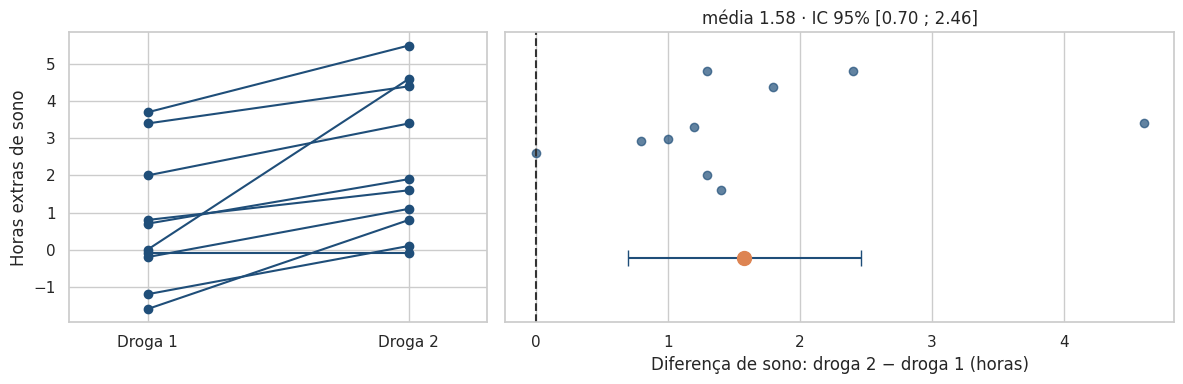

In [34]:
# esquerda: cada linha é um paciente; direita: as diferenças com média e IC
fig, axes = plt.subplots(1, 2, figsize=(12, 4), width_ratios=[1, 1.6])

# .T transpõe: cada coluna vira um paciente, e o plot desenha uma linha por paciente
axes[0].plot([0, 1], sleep_wide[["droga_1", "droga_2"]].T, color="#1F4E79", marker="o")
axes[0].set(xticks=[0, 1], xticklabels=["Droga 1", "Droga 2"], xlim=(-.3, 1.3),
            ylabel="Horas extras de sono")

# reaproveita a função do caso 1, com referência em 0 (nenhuma diferença)
plot_mean_ci(sleep_wide["D"], case3.confidence_interval(), 0,
             "Diferença de sono: droga 2 − droga 1 (horas)", axes[1])
plt.tight_layout()
plt.show()

In [35]:
# com só 10 diferenças, vale checar a normalidade de D
report("Shapiro-Wilk das diferenças", stats.shapiro(sleep_wide["D"]), stat="W")
# Wilcoxon = alternativa não paramétrica ao t pareado (usa postos)
report("Wilcoxon", stats.wilcoxon(sleep_wide["D"]), stat="T")

Shapiro-Wilk das diferenças: W = 0.830 · p = 0.033
Wilcoxon: T = 0.000 · p = 0.004


**Interpretação:** o pareado dá t ≈ 4,06 e p ≈ 0,003. Ignorando o pareamento, p ≈ 0,079. A diferença média é a mesma (1,58 h), mas o pareamento **cancela a variação entre pacientes** e o erro-padrão cai. As linhas sobem em 9 dos 10 pacientes. O Shapiro rejeita a normalidade de D (p ≈ 0,03), mas o Wilcoxon confirma (p ≈ 0,004). **Rejeitamos H₀**: a droga 2 rende cerca de 1,6 h a mais.

### Caso 4. ANOVA one-way

**Cenário:** o comprimento médio da sépala é o mesmo nas 3 espécies de íris?
- H₀: μ₁ = μ₂ = μ₃
- H₁: pelo menos uma média é diferente

F = variação **entre** grupos ÷ variação **dentro** dos grupos = [SQG/(k−1)] / [SQR/(N−k)].

In [36]:
# tabela da ANOVA passo a passo
grand_mean = iris["sepal_length"].mean()  # média geral das 150 flores

by_species = (
    iris
    .groupby("species")
    .sepal_length
    .agg(n="size", média="mean", dp="std")
)

# SQG: quanto cada média de espécie se afasta da média geral, ao quadrado, vezes o tamanho do grupo
ss_between = (by_species["n"] * (by_species["média"] - grand_mean) ** 2).sum()

# SQR: variação dentro de cada grupo; (n - 1)·s² é a soma dos desvios ao quadrado do grupo
ss_within = ((by_species["n"] - 1) * by_species["dp"] ** 2).sum()

k, N = len(by_species), len(iris)  # k = 3 grupos, N = 150 flores

In [37]:
# MQ (quadrado médio) = SQ / gl; F = MQ entre / MQ dentro
pd.DataFrame(
    {"SQ": [ss_between, ss_within], "gl": [k - 1, N - k]},
    index=["entre espécies", "dentro (resíduos)"],
).assign(MQ=lambda df: df["SQ"] / df["gl"]).round(3)

,SQ,gl,MQ
entre espécies,63.212,2,31.606
dentro (resíduos),38.956,147,0.265


In [38]:
# separa os três grupos (o _ ignora o nome da espécie que o groupby devolve)
setosa, versicolor, virginica = [
    group["sepal_length"] for _, group in iris.groupby("species")
]

anova = stats.f_oneway(setosa, versicolor, virginica)

report("ANOVA", anova, stat="F", df=(k - 1, N - k))
report("Levene", stats.levene(setosa, versicolor, virginica))

ANOVA: F = 119.265 · gl = (2, 147) · p < 0.001
Levene: estatística = 6.353 · p = 0.002


In [39]:
# a ANOVA só diz que ALGUMA média difere; o Tukey diz QUAIS pares diferem
# na saída: 0 = setosa, 1 = versicolor, 2 = virginica (ordem dos argumentos)
print(stats.tukey_hsd(setosa, versicolor, virginica))

Tukey's HSD Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -0.930     0.000    -1.174    -0.686
 (0 - 2)     -1.582     0.000    -1.826    -1.338
 (1 - 0)      0.930     0.000     0.686     1.174
 (1 - 2)     -0.652     0.000    -0.896    -0.408
 (2 - 0)      1.582     0.000     1.338     1.826
 (2 - 1)      0.652     0.000     0.408     0.896



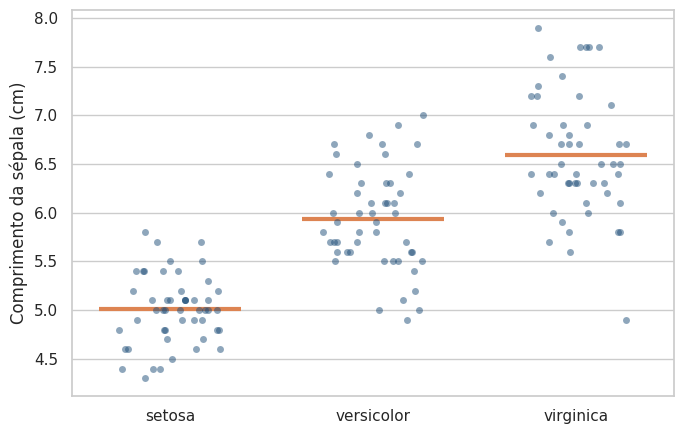

In [40]:
# comprimento da sépala por espécie (reaproveita a função do caso 2)
fig, ax = plt.subplots(figsize=(7, 4.5))
plot_group_means(iris, "species", "sepal_length", ["setosa", "versicolor", "virginica"],
                 "Comprimento da sépala (cm)", ax)
plt.tight_layout()
plt.show()

**Interpretação:** F ≈ 119,3, gl = (2, 147) e p < 0,001. **Rejeitamos H₀**, e o Tukey mostra que os 3 pares diferem. η² = SQG/(SQG+SQR) ≈ 0,62, ou seja, a espécie explica 62% da variação. ⚠️ O Levene (p ≈ 0,002) indica variâncias diferentes. O ideal seria a ANOVA de Welch + Games-Howell, mas aqui a conclusão não muda.

#### Por que não rodar vários testes t?
Cada teste tem 5% de chance de falso positivo, e essas chances se somam: 1 − (1 − 0,05)^c. Com 3 grupos são 3 pares, o que dá ≈ 14%. Vamos verificar simulando um mundo em que H₀ é verdadeira:

In [41]:
# falsos positivos com 3 testes t e com 1 ANOVA, sob H₀ verdadeira
rng = np.random.default_rng(2026)
values = iris["sepal_length"].to_numpy()
labels = iris["species"].to_numpy()
pairs = [(0, 1), (0, 2), (1, 2)]  # os 3 pares de espécies

any_t, anova_rejects = [], []
for _ in range(2_000):
    # embaralha as espécies: agora qualquer diferença entre grupos é puro acaso
    shuffled = rng.permutation(labels)
    groups = [values[shuffled == species] for species in np.unique(labels)]
    p_values = [stats.ttest_ind(groups[a], groups[b]).pvalue for a, b in pairs]
    # basta UM dos 3 testes t dar p <= 0,05 para concluir (erradamente) que há diferença
    any_t.append(min(p_values) <= .05)
    anova_rejects.append(stats.f_oneway(*groups).pvalue <= .05)  # *groups passa os 3 grupos

print(f"três testes t: algum falso positivo em {np.mean(any_t):.1%} dos sorteios")
print(f"uma ANOVA: falso positivo em {np.mean(anova_rejects):.1%} dos sorteios")

três testes t: algum falso positivo em 13.4% dos sorteios
uma ANOVA: falso positivo em 5.0% dos sorteios


Três testes t erram em ≈ 13% dos sorteios, e a ANOVA mantém os 5%. Por isso a regra é: **ANOVA primeiro, Tukey (post-hoc) depois**.

### Caso 5. Correlação de Pearson

**Cenário:** carros mais pesados (wt) gastam mais combustível (menos mpg)?
- H₀: ρ = 0 (sem relação linear)
- H₁: ρ ≠ 0

r varia de −1 a +1. Como referência: |r| < 0,3 é fraco, de 0,3 a 0,5 é moderado e > 0,5 é forte.

In [42]:
# Pearson pela fórmula: soma dos produtos dos desvios / raiz do produto das somas dos quadrados
dx = mtcars["wt"] - mtcars["wt"].mean()
dy = mtcars["mpg"] - mtcars["mpg"].mean()

r_manual = (dx * dy).sum() / np.sqrt((dx ** 2).sum() * (dy ** 2).sum())
case5 = stats.pearsonr(mtcars["wt"], mtcars["mpg"])

print(f"r calculado à mão = {r_manual:.3f}")
report("Pearson", case5, stat="r")

r calculado à mão = -0.868
Pearson: r = -0.868 · p < 0.001 · IC 95% [-0.93 ; -0.74]


In [43]:
# r não depende da unidade: converter o peso de libras para kg não muda nada
r_kg = stats.pearsonr(mtcars["wt"] * 453.6, mtcars["mpg"]).statistic

print(f"r com o peso em kg = {r_kg:.3f}")

r com o peso em kg = -0.868


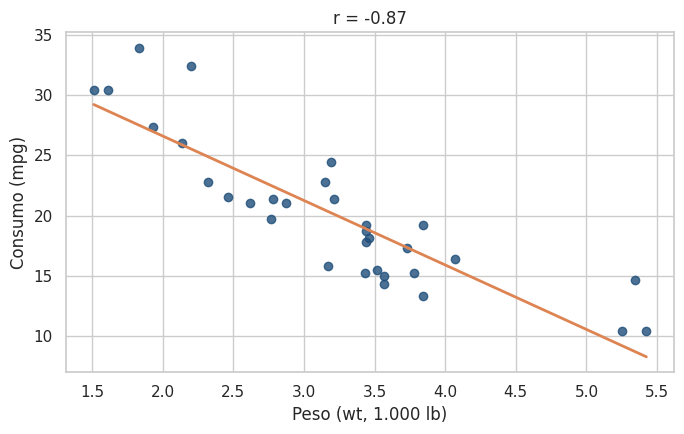

In [44]:
# consumo x peso, com a reta de mínimos quadrados
# polyfit com deg=1 ajusta uma reta e devolve (inclinação, intercepto)
slope, intercept = np.polyfit(mtcars["wt"], mtcars["mpg"], deg=1)
grid = np.linspace(mtcars["wt"].min(), mtcars["wt"].max(), 100)  # 100 pontos para desenhar a reta

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(mtcars["wt"], mtcars["mpg"], color="#1F4E79", alpha=.8)
ax.plot(grid, intercept + slope * grid, color="#DD8452", linewidth=2)
ax.set(title=f"r = {case5.statistic:.2f}", xlabel="Peso (wt, 1.000 lb)",
       ylabel="Consumo (mpg)")
plt.tight_layout()
plt.show()

**Interpretação:** r ≈ −0,87 e p < 0,001, uma relação forte e negativa: mais peso, menos mpg. **Rejeitamos H₀.**  
Pearson só enxerga relações lineares (para curvas monotônicas, use Spearman) e correlação não é causalidade

#### A transformação log melhora a correlação?

In [45]:
# Pearson com a potência na escala original e em log
log_hp = np.log(mtcars["hp"])

report("Pearson com hp", stats.pearsonr(mtcars["hp"], mtcars["mpg"]), stat="r")
report("Pearson com log(hp)", stats.pearsonr(log_hp, mtcars["mpg"]), stat="r")

Pearson com hp: r = -0.776 · p < 0.001 · IC 95% [-0.89 ; -0.59]
Pearson com log(hp): r = -0.849 · p < 0.001 · IC 95% [-0.92 ; -0.71]


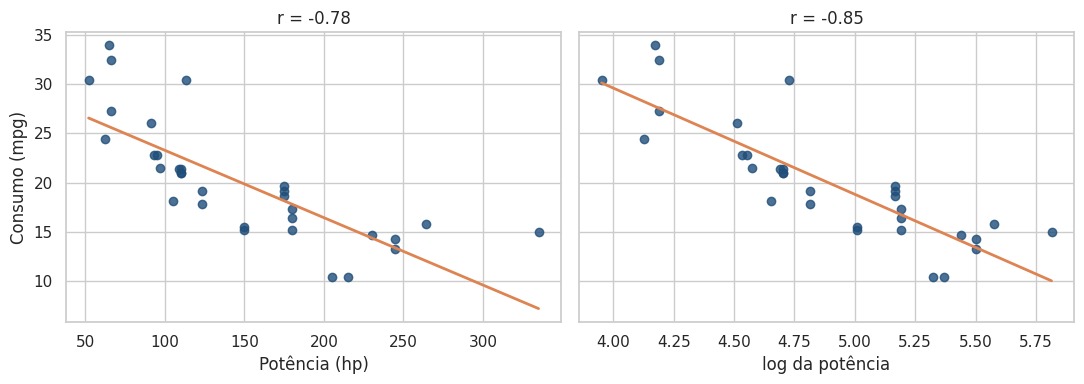

In [46]:
# consumo x potência nas duas escalas (sharey=True: os dois gráficos usam o mesmo eixo y)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, x, xlabel in zip(
    axes,
    [mtcars["hp"], log_hp],
    ["Potência (hp)", "log da potência"],
):
    slope, intercept = np.polyfit(x, mtcars["mpg"], deg=1)
    grid = np.linspace(x.min(), x.max(), 100)
    ax.scatter(x, mtcars["mpg"], color="#1F4E79", alpha=.8)
    ax.plot(grid, intercept + slope * grid, color="#DD8452", linewidth=2)
    ax.set(xlabel=xlabel, title=f"r = {stats.pearsonr(x, mtcars['mpg']).statistic:.2f}")

axes[0].set_ylabel("Consumo (mpg)")
plt.tight_layout()
plt.show()

Na escala original, os pontos formam uma curva. O log "estica" os valores baixos e "comprime" os altos, e a relação fica mais reta: r vai de −0,78 para −0,85.

### Caso 6. Teste Z de duas proporções

**Cenário:** a sobrevivência no Titanic foi diferente entre mulheres e homens?
- H₀: p_mulheres = p_homens
- H₁: p_mulheres ≠ p_homens

Z = (p̂₁ − p̂₂) / √[p̂(1−p̂)(1/n₁ + 1/n₂)], em que p̂ é a proporção **combinada** dos dois grupos. Condição: pelo menos 5 sucessos e 5 fracassos em cada grupo.

In [47]:
# sobreviventes, total e proporção por sexo
by_sex = (
    titanic
    .groupby("sex")
    .survived
    .agg(sobreviventes="sum", n="size")  # soma de 0/1 = número de sobreviventes
    .assign(
        # n·p̂ e n·(1-p̂) precisam ser >= 5 para valer a aproximação normal
        nao_sobreviventes=lambda df: df["n"] - df["sobreviventes"],
        proporcao=lambda df: df["sobreviventes"] / df["n"],
    )
)

by_sex.round(3)

,sobreviventes,n,nao_sobreviventes,proporcao
sex,,,,
female,233,314,81,0.742
male,109,577,468,0.189


In [48]:
# estatística Z pela fórmula e pelo statsmodels
p_pooled = by_sex["sobreviventes"].sum() / by_sex["n"].sum()           # proporção combinada (sob H₀)
se_pooled = np.sqrt(p_pooled * (1 - p_pooled) * (1 / by_sex["n"]).sum())  # erro-padrão
diff = by_sex.loc["female", "proporcao"] - by_sex.loc["male", "proporcao"]
z_manual = diff / se_pooled

# proportions_ztest recebe (sucessos de cada grupo, total de cada grupo) e devolve (Z, p)
case6 = proportions_ztest(by_sex["sobreviventes"], by_sex["n"])

print(f"proporção combinada = {p_pooled:.3f}")
print(f"Z calculado à mão = {z_manual:.2f}")
report("Z de duas proporções", case6, stat="Z")

proporção combinada = 0.384
Z calculado à mão = 16.22
Z de duas proporções: Z = 16.219 · p < 0.001


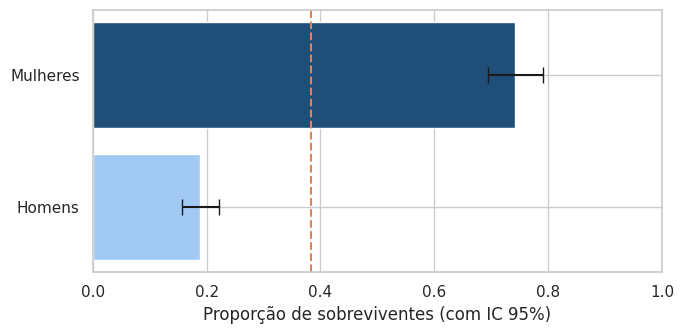

In [49]:
# proporção de sobreviventes por sexo, com intervalo de confiança
# proportion_confint devolve os limites inferior e superior do IC de cada proporção
low, high = proportion_confint(by_sex["sobreviventes"], by_sex["n"])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(["Homens", "Mulheres"], by_sex.loc[["male", "female"], "proporcao"],
        # xerr = distância da proporção até cada limite do IC
        xerr=[(by_sex["proporcao"] - low)[["male", "female"]],
              (high - by_sex["proporcao"])[["male", "female"]]],
        color=["#A1C9F4", "#1F4E79"], capsize=6)
ax.axvline(p_pooled, color="#DD8452", linestyle="--")  # taxa geral de sobrevivência
ax.set(xlim=(0, 1), xlabel="Proporção de sobreviventes (com IC 95%)")
plt.tight_layout()
plt.show()

**Interpretação:** 74,2% das mulheres sobreviveram, contra 18,9% dos homens. Z ≈ 16,2 e p < 0,001. **Rejeitamos H₀**: a regra "mulheres e crianças primeiro" aparece nos dados.

### Caso 7. Qui-quadrado de independência

**Cenário:** a classe da passagem (1ª, 2ª ou 3ª) tem relação com a sobrevivência?
- H₀: classe e sobrevivência são independentes
- H₁: estão associadas

χ² = Σ (O − E)² / E, com gl = (linhas − 1)(colunas − 1). Condição: frequências esperadas ≥ 5 (se não, use o exato de Fisher).

In [50]:
# tabela de contingência: conta passageiros em cada combinação de classe e desfecho
observed = pd.crosstab(titanic["pclass"], titanic["survived"])

observed

survived,0,1
pclass,,
1,80,136
2,97,87
3,372,119


In [51]:
# qui-quadrado, frequências esperadas e quanto cada célula contribui
# chi2_contingency calcula tudo: estatística, p, gl e as frequências esperadas (E)
case7 = stats.chi2_contingency(observed)

# E = total da linha × total da coluna / total geral (o que esperaríamos se fossem independentes)
expected = pd.DataFrame(
    case7.expected_freq, index=observed.index, columns=observed.columns
)
contributions = (observed - expected) ** 2 / expected  # parcela de cada célula no χ²

print(f"χ² = {case7.statistic:.2f}, gl = {case7.dof}, p = {case7.pvalue:.1e}")
pd.concat({"esperado": expected, "(O−E)²/E": contributions}, axis=1).round(1)

χ² = 102.89, gl = 2, p = 4.5e-23


esperado        (O−E)²/E      
survived        0      1        0     1
pclass                                 
1           133.1   82.9     21.2  34.0
2           113.4   70.6      2.4   3.8
3           302.5  188.5     15.9  25.6

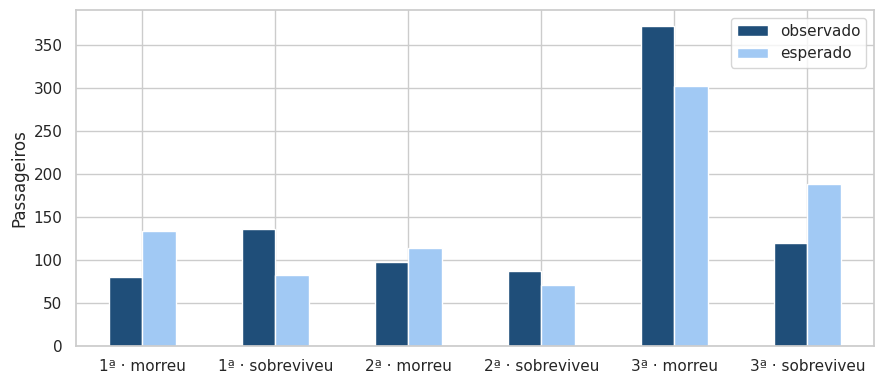

In [ ]:
# contagens observadas x esperadas sob independência
comparison = (
  pd.concat(
    # stack transforma a tabela em uma lista com uma linha por célula (classe, desfecho)
    {"observado": observed.stack(), "esperado": expected.stack()},
    axis=1,
  )
  .rename(index={0: "morreu", 1: "sobreviveu"}, level="survived")
)

fig, ax = plt.subplots(figsize=(9, 4))
comparison.plot.bar(ax=ax, color=["#1F4E79", "#A1C9F4"], rot=0)
ax.set_xticklabels([f"{c}ª · {d}" for c, d in comparison.index])
ax.set(xlabel="", ylabel="Passageiros")
plt.tight_layout()
plt.show()

# 5. Questões para casa

1. Repita o caso 2 comparando a massa corporal das espécies Adelie e Gentoo. Verifique as premissas antes de escolher entre o t clássico e o de Welch.

2. Aplique a ANOVA do caso 4 ao comprimento da pétala (petal_length). O que o teste de Levene indica? Compare o resultado com o teste de Kruskal-Wallis (stats.kruskal).

3. No Titanic, teste se a taxa de sobrevivência difere entre os portos de embarque (embarked). Qual teste você escolheu, e por quê?